# Self-auditing a video world model from sparse real observations

**Question.** A world model imagines the future. While it runs, how can an agent know how far its imagined rollout has drifted from reality, if it may look at only a tiny part of the real scene?

**Setting.** Diffusion Forcing (Chen, Monsó, Du, Simchowitz, Tedrake, Sitzmann; NeurIPS 2024), official pretrained Minecraft model. For every validation clip the model sees 2 real context frames and then imagines the rest. The audit may inspect **one real 32×32 patch per frame (1/16 of the pixels)** and must estimate the rollout's true drift: the full-frame MSE between imagined and real frames, averaged over the rollout.

**Method.** The patch-sampling audit from my BioSaccade-PEM work, transferred to a world model:

1. **Unbiased by construction.** The patch is drawn with known probability $q_j$ and weighted by $1/(J q_j)$ (Horvitz–Thompson), so the estimate is correct on average for *any* sampling rule.
2. **Control variates.** A predicted patch error $\mu_j$, computed only from information available *before* looking, is subtracted and its frame mean added back: $\hat\Delta_t = \bar\mu_t + (e_{tj} - \mu_{tj})/(J q_{tj})$. This lowers the variance and never adds bias.
3. **Label-free proxies.**
   - *Visual*: the texture and motion of the imagined patch, and the time since the last real frame.
   - *Disagreement*: how much independent rollouts of the same clip disagree on that patch. For a calibrated generative model, $\mathbb{E}\|g_r - x\|^2 = \mathbb{E}\|g_r - g_s\|^2$ for two independent samples $g_r, g_s$ and reality $x$, so disagreement is a principled predictor of the real error that needs no real data.
4. **Smart sampling.** Look more often where the residual error is predicted to be large: $q_j \propto \sqrt{\widehat{\mathbb{E}}[(e_j-\mu_j)^2]}$, plus an exploration floor.

**Rigour.** All predictors are fit *leaving the evaluated clip out* (no leakage). Variances are computed **exactly** and checked by Monte Carlo. Uncertainty comes from a **clip-level bootstrap**. A **negative control** (shuffled proxies) must show no gain. The **calibration** of the model's own disagreement is measured directly.

## 1. Configuration

In [1]:
import os, re, subprocess, sys, time, shutil, glob, threading

WORK = "/kaggle/working"
REPO = f"{WORK}/diffusion-forcing"
DUMP_ROOT = f"{WORK}/wm_audit_data"
RESULTS = f"{WORK}/wm_audit_results"
AUDIT = f"{WORK}/wm_audit.py"

N_RUNS = 3
MAX_BATCHES = 1
RUN_TIMEOUT_MIN = 45
GEN_BUDGET_MIN = 150
PATCH = 32
EPS = 0.1

WANDB_MODE = "offline"
WANDB_ENTITY = "usmanajmal659-islamia-university-of-bwp"
QUICKSTART_ID = "1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b"


def run(cmd, cwd=None, env=None, log=None, show=None, tail=40, timeout_min=None):
    """Run a shell command in a fresh process; stream selected lines, keep a full log, return the exit code."""
    lines, t0 = [], time.time()
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, text=True, bufsize=1, start_new_session=True,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    timer = None
    if timeout_min:
        timer = threading.Timer(60 * timeout_min, lambda: (print(f"!!! timeout after {timeout_min} min: stopping", flush=True),
                                                           os.killpg(p.pid, 9)))
        timer.start()
    fh = open(log, "w") if log else None
    last_beat, last_progress = time.time(), ""
    for line in p.stdout:
        if fh: fh.write(line)
        lines.append(line)
        if "Sampling" in line or "Validation" in line:
            last_progress = line.strip()
        if show is None or any(s in line for s in show):
            print(line.rstrip()[:400], flush=True)
        elif time.time() - last_beat > 300:
            print(f"[{(time.time() - t0) / 60:5.1f} min] {last_progress[:150]}", flush=True)
            last_beat = time.time()
    p.wait()
    if timer: timer.cancel()
    if fh: fh.close()
    if p.returncode != 0 and show is not None:
        print(f"--- command failed (exit {p.returncode}); last {tail} lines ---")
        print("".join(lines[-tail:]))
    return p.returncode

print("Python", sys.version.split()[0])

Python 3.13.15


## 2. Setup

Clone the official Diffusion Forcing repository, install its requirements and download the pretrained Minecraft checkpoint.

In [2]:
if not os.path.isdir(REPO):
    assert run(f"git clone --depth 1 https://github.com/buoyancy99/diffusion-forcing.git {REPO}") == 0
print("repository:", REPO)

Cloning into '/kaggle/working/diffusion-forcing'...
repository: /kaggle/working/diffusion-forcing


In [3]:
marker = f"{WORK}/.df_requirements_installed"
if not os.path.exists(marker):
    reqs = [l.strip() for l in open(f"{REPO}/requirements.txt") if l.strip() and not l.strip().startswith("#")]
    failed = []
    for r in reqs:
        name = re.split(r"[<>=!~\[ ;]", r)[0].lower()
        if name in {"torch", "torchvision", "torchaudio"}:
            continue
        if subprocess.run([sys.executable, "-m", "pip", "install", "-q", r],
                          capture_output=True, text=True).returncode != 0:
            failed.append(r)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown", "imageio"], capture_output=True)
    open(marker, "w").write("\n".join(failed))
    print("installed; failed pins:", failed or "none")
else:
    print("requirements already installed; failed pins:", open(marker).read() or "none")

installed; failed pins: none


In [4]:
assert run(f"{sys.executable} -c \"import hydra, omegaconf, lightning, wandb, torch, numpy, scipy, imageio, matplotlib; "
           f"print('torch', torch.__version__, '| numpy', numpy.__version__, '| GPU:', torch.cuda.is_available())\"",
           cwd=REPO) == 0

/usr/local/lib/python3.13/dist-packages/lightning/fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
torch 2.11.0+cu128 | numpy 2.5.3 | GPU: True


In [5]:
if not os.path.exists(f"{REPO}/outputs/minecraft.ckpt"):
    assert run(f"gdown {QUICKSTART_ID} -O quickstart_atten.tar.gz && tar -xzf quickstart_atten.tar.gz", cwd=REPO) == 0
n_val = len(glob.glob(f"{REPO}/data/minecraft/validation/**/*.mp4", recursive=True))
print("checkpoint:", os.path.exists(f"{REPO}/outputs/minecraft.ckpt"), "| validation videos:", n_val)

Downloading...
From (original): https://drive.google.com/uc?id=1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b
From (redirected): https://drive.google.com/uc?id=1xAOQxWcLzcFyD4zc0_rC9jGXe_uaHb7b&confirm=t&uuid=c979e452-54de-4f08-a8a0-bd4f618ee29a
To: /kaggle/working/diffusion-forcing/quickstart_atten.tar.gz

  0%|          | 0.00/592M [00:00<?, ?B/s]
  1%|          | 6.82M/592M [00:00<00:14, 41.1MB/s]
  3%|▎         | 20.4M/592M [00:00<00:06, 84.9MB/s]
  7%|▋         | 43.5M/592M [00:00<00:03, 143MB/s]
 10%|█         | 59.8M/592M [00:00<00:04, 127MB/s]
 12%|█▏        | 73.9M/592M [00:00<00:04, 121MB/s]
 16%|█▌        | 92.8M/592M [00:00<00:03, 136MB/s]
 19%|█▉        | 112M/592M [00:00<00:03, 151MB/s]
 23%|██▎       | 134M/592M [00:00<00:02, 171MB/s]
 26%|██▌       | 152M/592M [00:01<00:03, 134MB/s]
 28%|██▊       | 168M/592M [00:01<00:03, 140MB/s]
 31%|███       | 184M/592M [00:01<00:03, 136MB/s]
 35%|███▍      | 205M/592M [00:01<00:02, 154MB/s]
 38%|███▊      | 226M/592M [00:01<00:02, 170MB/s]
 42

## 3. Code

`df_dump_run.py` runs the repository's validation unchanged and saves the raw predicted and real videos; `wm_audit.py` implements the estimators, statistics and figures, followed by its self-tests.

In [6]:
%%writefile /kaggle/working/diffusion-forcing/df_dump_run.py
"""Run Diffusion Forcing's `python -m main ...` unchanged, but also save the raw float predictions and real videos that the repo passes to its video logger (utils.logging_utils.log_video)."""
import json
import os
import runpy
import sys

import numpy as np

sys.path.insert(0, os.getcwd())
DUMP = os.environ["DF_DUMP_DIR"]
os.makedirs(DUMP, exist_ok=True)

import utils.logging_utils as lu

if not hasattr(lu, "log_video"):
    raise SystemExit("utils.logging_utils.log_video not found: the repository layout changed.")
_original = lu.log_video
_count = {"n": 0}


def _to_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().float().cpu().numpy()
    return np.asarray(x, dtype=np.float32)


def log_video_and_dump(*args, **kwargs):
    named = [kwargs.get("observation_hat"), kwargs.get("observation_gt")]
    arrays = [a for a in list(args) + named if a is not None and len(getattr(a, "shape", ())) == 5]
    if len(arrays) >= 2:
        pred, gt = _to_numpy(arrays[0]), _to_numpy(arrays[1])
        path = os.path.join(DUMP, f"batch_{_count['n']:03d}.npz")
        np.savez_compressed(path, pred=pred.astype(np.float16), gt=gt.astype(np.float16))
        meta = {k: v for k, v in kwargs.items() if isinstance(v, (int, float, str))}
        meta.update(shape=list(pred.shape), file=os.path.basename(path))
        with open(os.path.join(DUMP, "meta.jsonl"), "a") as f:
            f.write(json.dumps(meta) + "\n")
        print(f"[dump] saved {path} with shape {pred.shape}", flush=True)
        _count["n"] += 1
    return _original(*args, **kwargs)


lu.log_video = log_video_and_dump
sys.argv = ["main.py"] + sys.argv[1:]
runpy.run_module("main", run_name="__main__", alter_sys=True)

Writing /kaggle/working/diffusion-forcing/df_dump_run.py


In [7]:
%%writefile /kaggle/working/wm_audit.py
"""Self-auditing a video world model with sparse real observations."""
import argparse
import glob
import hashlib
import json
import os
import sys

import numpy as np


def to_thwc_list(arr, layout="tbchw"):
    """Convert one dumped 5-D array to a list of per-clip videos (T, H, W, 3) in [0, 1]."""
    a = np.asarray(arr, dtype=np.float32)
    if a.ndim != 5:
        raise ValueError(f"expected a 5-D array, got shape {a.shape}")
    if layout == "tbchw":
        a = a.transpose(1, 0, 3, 4, 2)
    elif layout == "btchw":
        a = a.transpose(0, 1, 3, 4, 2)
    elif layout == "tbhwc":
        a = a.transpose(1, 0, 2, 3, 4)
    elif layout == "bthwc":
        pass
    else:
        raise ValueError(f"unknown layout {layout}")
    if a.shape[-1] != 3:
        raise ValueError(f"layout {layout} gives {a.shape}; channel axis is not last")
    return [np.clip(v, 0.0, 1.0) for v in a]


def _clip_key(gt):
    """Identity of a clip = hash of its real video (identical across runs)."""
    return hashlib.md5(np.round(gt, 3).astype(np.float16).tobytes()).hexdigest()[:16]


def load_dumps(root, layout="tbchw"):
    """runs[r][key] = (pred, gt) from <root>/run_*/batch_*.npz written by df_dump_run.py."""
    runs = []
    for rdir in sorted(glob.glob(os.path.join(root, "run_*"))):
        clips = {}
        for f in sorted(glob.glob(os.path.join(rdir, "batch_*.npz"))):
            z = np.load(f)
            preds, gts = to_thwc_list(z["pred"], layout), to_thwc_list(z["gt"], layout)
            for p, g in zip(preds, gts):
                clips.setdefault(_clip_key(g), (p, g))
        if clips:
            runs.append(clips)
    return runs


def load_gifs(root):
    """Fallback: wandb GIFs (prediction | real side by side). 8-bit palette, so noisier."""
    import imageio.v3 as iio
    runs = []
    for rdir in sorted(glob.glob(os.path.join(root, "**", "wandb", "run-*"), recursive=True)):
        files = sorted(glob.glob(os.path.join(rdir, "files", "media", "**", "*.gif"), recursive=True)
                       + glob.glob(os.path.join(rdir, "files", "media", "**", "*.mp4"), recursive=True))
        clips, seen = {}, set()
        for f in files:
            h = hashlib.md5(open(f, "rb").read()).hexdigest()
            if h in seen:
                continue
            seen.add(h)
            v = iio.imread(f).astype(np.float32) / 255.0
            if v.ndim != 4:
                continue
            w = v.shape[2] // 2
            p, g = v[:, :, :w, :3], v[:, :, w:2 * w, :3]
            clips.setdefault(_clip_key(g), (p, g))
        if clips:
            runs.append(clips)
    return runs


def load_any(data_root, gif_root=None, layout="tbchw"):
    runs = load_dumps(data_root, layout) if data_root and os.path.isdir(data_root) else []
    source = "float dumps"
    if not runs and gif_root:
        runs, source = load_gifs(gif_root), "wandb GIFs (8-bit, palette-quantized)"
    if not runs:
        raise SystemExit("No data found. Run the generation section first.")
    return runs, source


def _same_video(a, b, tol=2e-3):
    T = min(a.shape[0], b.shape[0])
    return a.shape[1:] == b.shape[1:] and float(((a[:T] - b[:T]) ** 2).mean()) < tol


def align(runs):
    """Match clips across runs by their real video (exact hash first, then near-identical content, which is needed for 8-bit GIFs whose palette differs per file)."""
    def dedupe(r):
        out = []
        for k, (p, g) in r.items():
            if not any(_same_video(g, g2) for _, g2 in out):
                out.append((p, g))
        return out
    ref = dedupe(runs[0])
    others = [dedupe(r) for r in runs[1:]]
    clips = []
    for p0, g0 in ref:
        preds = [p0]
        for o in others:
            match = [p for p, g in o if _same_video(g0, g)]
            if not match:
                break
            preds.append(match[0])
        if len(preds) == len(runs):
            T = min(p.shape[0] for p in preds + [g0])
            clips.append(dict(key=len(clips), gt=g0[:T], preds=[p[:T] for p in preds]))
    return clips


def context_frames(clips, tol=1e-6):
    """Number of leading frames copied from the real video (prediction == real) in every clip/run."""
    n = min(c["gt"].shape[0] for c in clips)
    for t in range(n):
        for c in clips:
            for p in c["preds"]:
                if float(((p[t] - c["gt"][t]) ** 2).mean()) > tol:
                    return t
    return n


def patchify(x, P):
    T, H, W, C = x.shape
    H2, W2 = (H // P) * P, (W // P) * P
    x = x[:, :H2, :W2]
    return x.reshape(T, H2 // P, P, W2 // P, P, C).transpose(0, 1, 3, 2, 4, 5).reshape(T, (H2 // P) * (W2 // P), -1)


FEATURES_VISUAL = ["texture", "motion", "time"]
FEATURES_ALL = ["disagreement", "texture", "motion", "time"]


def build_units(clips, P, n_ctx):
    """One unit = (clip, run). Arrays over evaluated frames t >= n_ctx: e[t,j] true patch error, feats."""
    units = []
    R = len(clips[0]["preds"])
    for ci, c in enumerate(clips):
        gt_p = patchify(c["gt"].astype(np.float64), P)
        pr_p = [patchify(p.astype(np.float64), P) for p in c["preds"]]
        T = gt_p.shape[0]
        for r in range(R):
            g = pr_p[r]
            e = ((g - gt_p) ** 2).mean(-1)
            tex = g.var(-1)
            mot = np.zeros_like(e)
            mot[1:] = ((g[1:] - g[:-1]) ** 2).mean(-1)
            if R > 1:
                dis = np.mean([((g - pr_p[s]) ** 2).mean(-1) for s in range(R) if s != r], axis=0)
            else:
                dis = np.full_like(e, np.nan)
            tt = np.broadcast_to(((np.arange(T) - n_ctx + 1) / max(T - n_ctx, 1))[:, None], e.shape)
            sl = slice(n_ctx, T)
            units.append(dict(clip=ci, run=r, e=e[sl], f=dict(disagreement=dis[sl], texture=tex[sl],
                                                              motion=mot[sl], time=np.array(tt[sl]))))
    return units


def design(u, names):
    cols = [u["f"][n].ravel() for n in names] + [np.ones(u["e"].size)]
    return np.stack(cols, 1)


def fit_models(train, names, ridge=1e-8):
    """Least-squares mean model for e, and a second-moment model for the residual (for sampling)."""
    X = np.concatenate([design(u, names) for u in train])
    y = np.concatenate([u["e"].ravel() for u in train])
    sc = X.std(0)
    sc[sc == 0] = 1.0
    Xs = X / sc
    A = Xs.T @ Xs + ridge * np.eye(Xs.shape[1])
    w = np.linalg.solve(A, Xs.T @ y) / sc
    r2 = (y - X @ w) ** 2
    v = np.linalg.solve(A, Xs.T @ r2) / sc
    return w, v


def frame_estimates(e_t, mu_t, q_t):
    """All J possible single-patch estimates of the frame-mean error at one frame."""
    J = e_t.size
    return mu_t.mean() + (e_t - mu_t) / (J * q_t)


def exact_relvar(e, mu, q, k=1):
    """Exact relative variance of the rollout-mean estimate with k independent patches per frame."""
    T = e.shape[0]
    var = 0.0
    for t in range(T):
        est = frame_estimates(e[t], mu[t], q[t])
        var += float((q[t] * (est - e[t].mean()) ** 2).sum())
    var /= (k * T * T)
    return var / float(e.mean()) ** 2


def exact_bias(e, mu, q):
    out = 0.0
    for t in range(e.shape[0]):
        out += float((q[t] * frame_estimates(e[t], mu[t], q[t])).sum() - e[t].mean())
    return out / e.shape[0]


def sampling_from_m2(m2, eps):
    s = np.sqrt(np.clip(m2, 1e-12, None))
    q = s / s.sum(1, keepdims=True)
    return (1 - eps) * q + eps / q.shape[1]


def method_plan(units, have_dis, eps, seed=0):
    """For every unit, (mu, q) of each method. Models are fit leaving the unit's CLIP out entirely."""
    rng = np.random.default_rng(seed)
    clips = sorted({u["clip"] for u in units})
    plans = {}
    for c in clips:
        train = [u for u in units if u["clip"] != c]
        test = [u for u in units if u["clip"] == c]
        models = {"visual": fit_models(train, FEATURES_VISUAL)}
        if have_dis:
            models["all"] = fit_models(train, FEATURES_ALL)
        shuf = []
        for u in train:
            perm = np.argsort(rng.random(u["e"].shape), axis=1)
            shuf.append(dict(e=u["e"], f={n: np.take_along_axis(u["f"][n], perm, 1) for n in FEATURES_VISUAL}))
        models["shuffled"] = fit_models(shuf, FEATURES_VISUAL)
        for u in test:
            shp = u["e"].shape
            J = shp[1]
            uni = np.full(shp, 1.0 / J)
            mu = {}
            m2 = {}
            for name, (w, v) in models.items():
                feats = FEATURES_ALL if name == "all" else FEATURES_VISUAL
                src = u
                if name == "shuffled":
                    perm = np.argsort(rng.random(shp), axis=1)
                    src = dict(e=u["e"], f={n: np.take_along_axis(u["f"][n], perm, 1) for n in FEATURES_VISUAL})
                X = design(src, feats)
                mu[name] = (X @ w).reshape(shp)
                m2[name] = (X @ v).reshape(shp)
            p = {
                "Uniform (Horvitz-Thompson)": (np.zeros(shp), uni),
                "Uniform + CV[visual]": (mu["visual"], uni),
                "Smart + CV[visual]": (mu["visual"], sampling_from_m2(m2["visual"], eps)),
                "Negative control: CV[shuffled proxies]": (mu["shuffled"], uni),
            }
            if have_dis:
                p["Uniform + CV[visual+disagreement]"] = (mu["all"], uni)
                p["Smart + CV[visual+disagreement]"] = (mu["all"], sampling_from_m2(m2["all"], eps))
            best = mu["all"] if have_dis else mu["visual"]
            p["Oracle Neyman (not deployable)"] = (best, sampling_from_m2((u["e"] - best) ** 2, eps))
            plans[(u["clip"], u["run"])] = p
    return plans


def bootstrap_ci(per_clip, B=5000, seed=1, stat=np.mean):
    rng = np.random.default_rng(seed)
    x = np.asarray(per_clip, float)
    idx = rng.integers(0, len(x), (B, len(x)))
    s = np.array([stat(x[i]) for i in idx])
    return float(np.quantile(s, 0.025)), float(np.quantile(s, 0.975))


def bootstrap_ratio(num, den, B=5000, seed=2):
    rng = np.random.default_rng(seed)
    num, den = np.asarray(num, float), np.asarray(den, float)
    idx = rng.integers(0, len(num), (B, len(num)))
    r = num[idx].mean(1) / den[idx].mean(1)
    return float(num.mean() / den.mean()), float(np.quantile(r, 0.025)), float(np.quantile(r, 0.975))


def analyze(data_root, out, gif_root=None, P=32, eps=0.1, layout="tbchw", mc_reps=2000):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    os.makedirs(out, exist_ok=True)
    runs, source = load_any(data_root, gif_root, layout)
    clips = align(runs)
    R, C = len(runs), len(clips)
    if C < 3:
        raise SystemExit(f"Only {C} clips found in all runs; need at least 3 for leave-one-clip-out.")
    n_ctx = context_frames(clips)
    T, H, W, _ = clips[0]["gt"].shape
    J = (H // P) * (W // P)
    have_dis = R > 1
    print(f"Data: {source}; runs={R}, clips in all runs={C}, frames={T}, context frames={n_ctx}, "
          f"frame {H}x{W}, patch {P}x{P} -> J={J} patches (budget = 1/{J} of the pixels per frame)")

    units = build_units(clips, P, n_ctx)
    plans = method_plan(units, have_dis, eps)
    methods = list(next(iter(plans.values())).keys())

    rv = {m: np.zeros((C, R)) for m in methods}
    bias = {m: 0.0 for m in methods}
    for u in units:
        for m, (mu, q) in plans[(u["clip"], u["run"])].items():
            rv[m][u["clip"], u["run"]] = exact_relvar(u["e"], mu, q)
            bias[m] = max(bias[m], abs(exact_bias(u["e"], mu, q)) / float(u["e"].mean()))
    per_clip = {m: rv[m].mean(1) for m in methods}

    rng = np.random.default_rng(7)
    u0 = units[0]
    mc_check = {}
    for m, (mu, q) in plans[(u0["clip"], u0["run"])].items():
        Tn, Jn = u0["e"].shape
        est = np.zeros(mc_reps)
        for t in range(Tn):
            js = np.array([rng.choice(Jn, p=q[t]) for _ in range(mc_reps)])
            est += frame_estimates(u0["e"][t], mu[t], q[t])[js]
        est /= Tn
        truth = u0["e"].mean()
        mc_check[m] = dict(mc_bias_pct=float(100 * (est.mean() - truth) / truth),
                           mc_relrmse_pct=float(100 * np.sqrt(((est - truth) ** 2).mean()) / truth),
                           exact_relrmse_pct=float(100 * np.sqrt(rv[m][u0["clip"], u0["run"]])))

    base = "Uniform (Horvitz-Thompson)"
    rows = []
    for m in methods:
        rel = 100 * np.sqrt(per_clip[m].mean())
        lo, hi = bootstrap_ci(per_clip[m], stat=lambda x: 100 * np.sqrt(np.mean(x)))
        ratio, rlo, rhi = bootstrap_ratio(per_clip[m], per_clip[base])
        rows.append(dict(method=m, rel_rmse_pct=rel, ci_lo=lo, ci_hi=hi, var_ratio=ratio,
                         ratio_lo=rlo, ratio_hi=rhi, budget_equiv=1 / ratio, max_abs_bias_pct=100 * bias[m]))

    drift = np.array([[((p - c["gt"]) ** 2).mean(axis=(1, 2, 3)) for p in c["preds"]] for c in clips])
    dis_curve = None
    if have_dis:
        dis_curve = np.array([[np.mean([((c["preds"][r] - c["preds"][s]) ** 2).mean(axis=(1, 2, 3))
                                         for s in range(R) if s != r], axis=0) for r in range(R)] for c in clips])

    calib = {}
    if have_dis:
        E = np.concatenate([u["e"].ravel() for u in units])
        D = np.concatenate([u["f"]["disagreement"].ravel() for u in units])
        from scipy.stats import spearmanr, pearsonr
        calib = dict(slope_through_origin=float((E * D).sum() / (D * D).sum()),
                     pearson=float(pearsonr(E, D)[0]), spearman=float(spearmanr(E, D)[0]),
                     mean_error=float(E.mean()), mean_disagreement=float(D.mean()))
    from scipy.stats import spearmanr as _sp
    Eall = np.concatenate([u["e"].ravel() for u in units])
    proxy_corr = {n: float(_sp(Eall, np.concatenate([u["f"][n].ravel() for u in units]))[0])
                  for n in (FEATURES_ALL if have_dis else FEATURES_VISUAL)}

    tt = np.arange(T) - n_ctx + 1
    fig, ax = plt.subplots(figsize=(7, 3.8))
    flat = drift.reshape(-1, T)
    for row in flat:
        ax.plot(tt, row, color="0.75", lw=0.8)
    m = drift.mean(axis=(1)).mean(0)
    boot = np.array([drift[np.random.default_rng(i).integers(0, C, C)].mean(axis=(0, 1)) for i in range(2000)])
    ax.plot(tt, m, color="C0", lw=2.2, label=f"mean over {C} clips x {R} runs")
    ax.fill_between(tt, np.quantile(boot, .025, 0), np.quantile(boot, .975, 0), color="C0", alpha=.25,
                    label="95% clip-bootstrap CI")
    if dis_curve is not None:
        ax.plot(tt, dis_curve.mean(axis=(0, 1)), "--", color="C3", lw=2,
                label="model's own disagreement (no real data)")
    ax.axvline(0.5, color="k", ls=":", lw=1)
    ax.set_xlabel("frames after the last real context frame (<=0: real context)")
    ax.set_ylabel("full-frame MSE vs real video")
    ax.set_title("World-model drift during an imagined rollout")
    ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig1_drift.png"), dpi=150)
    plt.close(fig)

    if have_dis:
        E = np.concatenate([u["e"].ravel() for u in units])
        D = np.concatenate([u["f"]["disagreement"].ravel() for u in units])
        bins = np.quantile(D, np.linspace(0, 1, 11))
        idx = np.clip(np.digitize(D, bins[1:-1]), 0, 9)
        bx = np.array([D[idx == b].mean() for b in range(10)])
        by = np.array([E[idx == b].mean() for b in range(10)])
        fig, ax = plt.subplots(figsize=(4.6, 4.2))
        ax.scatter(D, E, s=3, alpha=.15, color="0.5", label="patches")
        ax.plot(bx, by, "o-", color="C3", label="binned mean")
        lim = [0, float(max(np.quantile(D, .99), np.quantile(E, .99)))]
        ax.plot(lim, lim, "k--", lw=1, label="perfect calibration (y = x)")
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_xlabel("disagreement between rollouts (label-free)")
        ax.set_ylabel("true patch error vs real video")
        ax.set_title(f"Calibration (Spearman {calib['spearman']:.2f})")
        ax.legend(fontsize=7)
        ax.grid(alpha=.3)
        fig.tight_layout()
        fig.savefig(os.path.join(out, "fig2_calibration.png"), dpi=150)
        plt.close(fig)

    order = [r for r in rows if not r["method"].startswith("Oracle")] + [r for r in rows if r["method"].startswith("Oracle")]
    fig, ax = plt.subplots(figsize=(8, 0.5 + 0.5 * len(order)))
    y = np.arange(len(order))[::-1]
    for yi, r in zip(y, order):
        col = "0.6" if r["method"].startswith(("Oracle", "Negative")) else ("C3" if "disagreement" in r["method"] else "C0")
        ax.barh(yi, r["rel_rmse_pct"], color=col)
        ax.errorbar(r["rel_rmse_pct"], yi, xerr=[[r["rel_rmse_pct"] - r["ci_lo"]], [r["ci_hi"] - r["rel_rmse_pct"]]],
                    color="k", capsize=3)
    ax.set_yticks(y, [r["method"] for r in order], fontsize=8)
    ax.set_xlabel("relative error of the rollout-drift audit (%), 1 patch per frame; lower is better")
    ax.set_title("Auditing drift from one real patch per frame (95% clip-bootstrap CI)")
    ax.grid(axis="x", alpha=.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig3_estimators.png"), dpi=150)
    plt.close(fig)

    ks = np.array([1, 2, 3, 4, 6, 8])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    show = [base, "Uniform + CV[visual]", "Smart + CV[visual]"] + (
        ["Smart + CV[visual+disagreement]"] if have_dis else [])
    for mname in show:
        r0 = next(r for r in rows if r["method"] == mname)
        ax.plot(ks, r0["rel_rmse_pct"] / np.sqrt(ks), "o-", label=mname)
    ax.set_xlabel("real patches inspected per frame (k)")
    ax.set_ylabel("relative error (%)")
    ax.set_title("Accuracy versus observation budget")
    ax.grid(alpha=.3)
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig4_budget.png"), dpi=150)
    plt.close(fig)

    ci, ri = np.unravel_index(np.argmax(drift[:, :, -1]), drift.shape[:2])
    c = clips[ci]
    t = n_ctx + (T - n_ctx) // 2
    u = next(x for x in units if x["clip"] == ci and x["run"] == ri)
    best_m = "Smart + CV[visual+disagreement]" if have_dis else "Smart + CV[visual]"
    q = plans[(ci, ri)][best_m][1][t - n_ctx]
    gh, gw = H // P, W // P
    panels = [("real (evaluator only)", c["gt"][t]), ("imagined by the model", c["preds"][ri][t]),
              ("true error", ((c["preds"][ri][t] - c["gt"][t]) ** 2).mean(-1))]
    if have_dis:
        panels.append(("disagreement (label-free)", u["f"]["disagreement"][t - n_ctx].reshape(gh, gw)))
    panels.append(("where the audit looks (q)", q.reshape(gh, gw)))
    fig, axs = plt.subplots(1, len(panels), figsize=(3 * len(panels), 3.1))
    for a, (title, img) in zip(axs, panels):
        a.imshow(img, cmap=None if img.ndim == 3 else "magma", interpolation="nearest")
        a.set_title(title, fontsize=9)
        a.axis("off")
    fig.suptitle(f"Example: clip {ci}, run {ri}, frame {t - n_ctx + 1} after context", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig5_example.png"), dpi=150)
    plt.close(fig)

    lines = ["| Method | Relative error (%) | 95% CI | Variance vs uniform | 95% CI | Equivalent budget | Max bias (%) |",
             "|---|---|---|---|---|---|---|"]
    for r in rows:
        lines.append(f"| {r['method']} | {r['rel_rmse_pct']:.1f} | {r['ci_lo']:.1f}-{r['ci_hi']:.1f} | "
                     f"{r['var_ratio']:.2f} | {r['ratio_lo']:.2f}-{r['ratio_hi']:.2f} | x{r['budget_equiv']:.2f} | "
                     f"{r['max_abs_bias_pct']:.1e} |")
    verdict = []
    for r in rows:
        if r["method"] == base or r["method"].startswith("Oracle"):
            continue
        sig = r["ratio_hi"] < 1
        verdict.append(f"- **{r['method']}**: variance x{r['var_ratio']:.2f} of uniform "
                       f"(95% CI {r['ratio_lo']:.2f}-{r['ratio_hi']:.2f}), i.e. the accuracy of "
                       f"{r['budget_equiv']:.2f} uniform patches per frame. "
                       + ("Reduction is statistically clear (CI below 1)." if sig else
                          "Not statistically distinguishable from uniform with this many clips."))
    if have_dis:
        verdict.append(f"- **Calibration**: patch-level Spearman correlation between rollout disagreement and the "
                       f"true error is {calib['spearman']:.2f}; slope through origin {calib['slope_through_origin']:.2f} "
                       f"(1.0 = perfectly calibrated; >1 = the model is over-confident, its samples agree more than "
                       f"they match reality).")
    verdict.append("- **Unbiasedness**: the exact expectation of every estimator equals the truth to numerical "
                   "precision (max bias column), including the negative control, as the theory requires.")
    verdict.append(f"- **Proxy relevance** (Spearman with the true patch error): " +
                   ", ".join(f"{k} {v:.2f}" for k, v in proxy_corr.items()))
    md = (f"**Data**: {source}; {R} run(s) x {C} clips; {T - n_ctx} imagined frames per clip after "
          f"{n_ctx} real context frames; {J} patches per frame, 1 inspected.\n\n"
          + "\n".join(lines) + "\n\n" + "\n".join(verdict) + "\n")
    open(os.path.join(out, "results.md"), "w").write(md)
    json.dump(dict(source=source, runs=R, clips=C, frames=T, context=n_ctx, patch=P, patches_per_frame=J,
                   eps=eps, rows=rows, calibration=calib, proxy_spearman=proxy_corr, mc_check=mc_check,
                   drift_mean_per_frame=drift.mean(axis=(0, 1)).tolist()),
              open(os.path.join(out, "summary.json"), "w"), indent=2)
    with open(os.path.join(out, "per_clip_relvar.csv"), "w") as f:
        f.write("method,clip,run,relative_variance\n")
        for mname in methods:
            for ci_ in range(C):
                for r_ in range(R):
                    f.write(f"{mname},{ci_},{r_},{rv[mname][ci_, r_]:.6g}\n")
    print(md)
    print("Monte Carlo check of the exact formulas (one clip):")
    for mname, d in mc_check.items():
        print(f"  {mname:42s} MC bias {d['mc_bias_pct']:+.2f}%  MC rel.err {d['mc_relrmse_pct']:.1f}%  "
              f"exact {d['exact_relrmse_pct']:.1f}%")
    return rows


def inspect(data_root, gif_root=None, layout="tbchw"):
    if data_root and os.path.isdir(data_root) and gif_root:
        check_layout(data_root, gif_root)
    runs, source = load_any(data_root, gif_root, layout)
    print("Source:", source)
    for i, r in enumerate(runs):
        shapes = {v[0].shape for v in r.values()}
        print(f"  run {i}: {len(r)} clips, shapes {shapes}")
    clips = align(runs)
    print(f"Clips present in every run (same real video): {len(clips)}")
    if not clips:
        raise SystemExit("No clip appears in every run: the runs used different validation clips.")
    if len(runs) > 1 and len(clips) < min(len(r) for r in runs):
        print("  WARNING: some clips differ between runs; only common clips are analysed.")
    n_ctx = context_frames(clips)
    print(f"Leading real context frames: {n_ctx}")
    if len(runs) > 1 and clips:
        c = clips[0]
        d = [float(((c['preds'][0][n_ctx:] - p[n_ctx:]) ** 2).mean()) for p in c["preds"][1:]]
        print(f"Different futures across runs (clip 0, MSE between run 0 and others): {np.round(d, 4)}")


def check_layout(data_root, gif_root):
    """Confirm the axis order of the dumps by matching them to the wandb GIFs of the same runs."""
    f = sorted(glob.glob(os.path.join(data_root, "run_*", "batch_*.npz")))
    if not f or not gif_root:
        return None
    gifs = load_gifs(gif_root)
    gif_preds = [p for r in gifs for p, _ in r.values()]
    if not gif_preds:
        return None
    raw = np.load(f[0])["pred"]
    best = None
    for lay in ["tbchw", "btchw", "tbhwc", "bthwc"]:
        try:
            vids = to_thwc_list(raw, lay)
        except ValueError:
            continue
        for v in vids:
            for g in gif_preds:
                if v.shape == g.shape:
                    d = float(((v - g) ** 2).mean())
                    if best is None or d < best[1]:
                        best = (lay, d)
    if best:
        print(f"Layout check against wandb GIFs: best layout '{best[0]}' (MSE to a GIF {best[1]:.2e}; "
              f"values below ~1e-3 mean an exact match up to 8-bit GIF quantization)")
    else:
        print("Layout check: no GIF with the same shape as the dumps (GIFs may be subsampled); "
              "keeping the default layout 'tbchw' (time, batch, channel, height, width).")
    return best


def _synthetic(root, R=3, C=6, T=10, n_ctx=2, seed=0):
    rng = np.random.default_rng(seed)
    for r in range(R):
        os.makedirs(os.path.join(root, f"run_{r}"), exist_ok=True)
    gts = rng.random((C, T, 64, 64, 3)).astype(np.float32)
    gts = (gts + np.roll(gts, 1, 2) + np.roll(gts, 1, 3)) / 3
    for r in range(R):
        preds = gts.copy()
        for t in range(n_ctx, T):
            amp = 0.03 * (t - n_ctx + 1)
            mask = np.zeros((C, 64, 64, 1), np.float32)
            mask[:, :32] = 1.0
            preds[:, t] = np.clip(gts[:, t] + amp * (0.4 + mask) * rng.standard_normal(gts[:, t].shape), 0, 1)
        for b in range(0, C, 4):
            sl = slice(b, b + 4)
            np.savez_compressed(os.path.join(root, f"run_{r}", f"batch_{b // 4:03d}.npz"),
                                pred=preds[sl].transpose(1, 0, 4, 2, 3).astype(np.float16),
                                gt=gts[sl].transpose(1, 0, 4, 2, 3).astype(np.float16))


def selftest():
    import tempfile
    rng = np.random.default_rng(0)
    for _ in range(200):
        J = rng.integers(2, 40)
        e, mu = rng.random(J), rng.normal(size=J)
        q = rng.random(J) + 1e-3
        q /= q.sum()
        assert abs((q * frame_estimates(e, mu, q)).sum() - e.mean()) < 1e-10
    e = rng.random((5, 16))
    mu = e + rng.normal(scale=.2, size=e.shape)
    q = sampling_from_m2((e - mu) ** 2 + .01, .1)
    reps = 40000
    est = np.zeros(reps)
    for t in range(5):
        est += frame_estimates(e[t], mu[t], q[t])[np.array([rng.choice(16, p=q[t]) for _ in range(reps)])]
    est /= 5
    mc = ((est - e.mean()) ** 2).mean() / e.mean() ** 2
    ex = exact_relvar(e, mu, q)
    assert abs(mc / ex - 1) < 0.05, (mc, ex)
    x = rng.random((3, 64, 64, 3))
    assert np.allclose(patchify(x, 16).mean(-1).mean(-1), x.mean(axis=(1, 2, 3)))
    with tempfile.TemporaryDirectory() as d:
        _synthetic(os.path.join(d, "dumps"))
        inspect(os.path.join(d, "dumps"))
        rows = analyze(os.path.join(d, "dumps"), os.path.join(d, "out"), P=16, mc_reps=300)
        assert all(r["max_abs_bias_pct"] < 1e-6 for r in rows)
        assert set(os.listdir(os.path.join(d, "out"))) >= {"fig1_drift.png", "fig3_estimators.png", "results.md"}
    print("\nALL SELF-TESTS PASSED")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("cmd", choices=["selftest", "inspect", "analyze"])
    ap.add_argument("--data")
    ap.add_argument("--gif-root")
    ap.add_argument("--out", default="results")
    ap.add_argument("--patch", type=int, default=32)
    ap.add_argument("--eps", type=float, default=0.1)
    ap.add_argument("--layout", default="tbchw")
    a = ap.parse_args()
    if a.cmd == "selftest":
        selftest()
    elif a.cmd == "inspect":
        inspect(a.data, a.gif_root, a.layout)
    else:
        analyze(a.data, a.out, a.gif_root, a.patch, a.eps, a.layout)

Writing /kaggle/working/wm_audit.py


In [8]:
assert run(f"{sys.executable} {AUDIT} selftest", cwd=WORK, show=["PASSED", "Error", "assert", "Traceback"]) == 0

ALL SELF-TESTS PASSED


## 4. Rollout generation

Each of the 8 validation clips is rolled out three times from the same two real context frames.

In [9]:
os.makedirs(DUMP_ROOT, exist_ok=True)
gen_start = time.time()
for i in range(N_RUNS):
    out = f"{DUMP_ROOT}/run_{i}"
    if os.path.exists(f"{out}/DONE"):
        print(f"run {i}: already done, skipping"); continue
    used = (time.time() - gen_start) / 60
    if used > GEN_BUDGET_MIN:
        print(f"Generation budget of {GEN_BUDGET_MIN} min reached ({used:.0f} min used): not starting run {i}. "
              "Re-run this cell in a new session to continue; finished runs are kept."); break
    shutil.rmtree(out, ignore_errors=True)
    env = dict(os.environ, TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD="1", CUDA_VISIBLE_DEVICES="0",
               WANDB_MODE=WANDB_MODE, DF_DUMP_DIR=out, HYDRA_FULL_ERROR="1")
    cmd = (f"{sys.executable} df_dump_run.py +name=wm_audit_run{i} load=outputs/minecraft.ckpt "
           f"experiment.tasks=[validation] experiment.validation.limit_batch={MAX_BATCHES} "
           f"wandb.entity={WANDB_ENTITY}")
    t0 = time.time()
    rc = run(cmd, cwd=REPO, env=env, log=f"{WORK}/generation_run{i}.log", timeout_min=RUN_TIMEOUT_MIN,
             show=["[dump]", "validation/mse", "validation/psnr", "Error", "Traceback"])
    n = len(glob.glob(f"{out}/batch_*.npz"))
    mins = (time.time() - t0) / 60
    print(f"run {i}: exit {rc}, {n} dumped batch(es), {mins:.1f} min")
    if n > 0:
        open(f"{out}/DONE", "w").write("ok" if rc == 0 else f"partial (exit {rc})")
        if i == 0:
            print(f"-> estimated time for all {N_RUNS} runs: about {mins * N_RUNS:.0f} min")
    else:
        raise RuntimeError(f"run {i} produced no data; see {WORK}/generation_run{i}.log")
print(f"generation finished: {(time.time() - gen_start) / 60:.0f} min in this session")

[ 25.6 min] Validation DataLoader 0: 100%|██████████| 1/1 [25:10<00:00,  0.00it/s][dump] saved /kaggle/working/wm_audit_data/run_0/batch_000.npz with shape (10, 8
│      validation/mse       │    0.02939225547015667    │
│      validation/psnr      │     21.33827018737793     │
wandb:      validation/mse ▁
wandb:     validation/psnr ▁
wandb:      validation/mse 0.02939
wandb:     validation/psnr 21.33827
run 0: exit 0, 1 dumped batch(es), 25.7 min
-> estimated time for all 3 runs: about 77 min
[ 25.7 min] Validation DataLoader 0: 100%|██████████| 1/1 [25:17<00:00,  0.00it/s][dump] saved /kaggle/working/wm_audit_data/run_1/batch_000.npz with shape (10, 8
│      validation/mse       │   0.030606379732489586    │
│      validation/psnr      │    21.162477493286133     │
wandb:      validation/mse ▁
wandb:     validation/psnr ▁
wandb:      validation/mse 0.03061
wandb:     validation/psnr 21.16248
run 1: exit 0, 1 dumped batch(es), 25.8 min
[ 25.7 min] Validation DataLoader 0: 100%|███████

## 5. Data check

Tensor layout, clip alignment across runs, number of context frames and diversity of the generated futures.

In [10]:
assert run(f"{sys.executable} {AUDIT} inspect --data {DUMP_ROOT} --gif-root {REPO}/outputs", cwd=WORK) == 0

Source: float dumps
  run 0: 8 clips, shapes {(10, 128, 128, 3)}
  run 1: 8 clips, shapes {(10, 128, 128, 3)}
  run 2: 8 clips, shapes {(10, 128, 128, 3)}
Clips present in every run (same real video): 8
Leading real context frames: 2
Different futures across runs (clip 0, MSE between run 0 and others): [0.0168 0.0141]


## 6. Analysis

Leave-one-clip-out fitting of the error predictors, exact estimator variances and clip-level bootstrap confidence intervals.

In [11]:
assert run(f"{sys.executable} {AUDIT} analyze --data {DUMP_ROOT} --gif-root {REPO}/outputs "
           f"--out {RESULTS} --patch {PATCH} --eps {EPS}", cwd=WORK) == 0

Data: float dumps; runs=3, clips in all runs=8, frames=10, context frames=2, frame 128x128, patch 32x32 -> J=16 patches (budget = 1/16 of the pixels per frame)
**Data**: float dumps; 3 run(s) x 8 clips; 8 imagined frames per clip after 2 real context frames; 16 patches per frame, 1 inspected.

| Method | Relative error (%) | 95% CI | Variance vs uniform | 95% CI | Equivalent budget | Max bias (%) |
|---|---|---|---|---|---|---|
| Uniform (Horvitz-Thompson) | 52.7 | 44.9-60.2 | 1.00 | 1.00-1.00 | x1.00 | 0.0e+00 |
| Uniform + CV[visual] | 46.0 | 36.4-53.9 | 0.76 | 0.57-1.06 | x1.31 | 1.3e-14 |
| Smart + CV[visual] | 38.4 | 32.9-44.5 | 0.53 | 0.44-0.61 | x1.88 | 2.6e-14 |
| Negative control: CV[shuffled proxies] | 52.7 | 45.0-60.2 | 1.00 | 1.00-1.01 | x1.00 | 1.7e-14 |
| Uniform + CV[visual+disagreement] | 38.7 | 31.0-47.4 | 0.54 | 0.37-0.71 | x1.85 | 1.2e-14 |
| Smart + CV[visual+disagreement] | 30.9 | 24.8-37.0 | 0.35 | 0.25-0.46 | x2.90 | 1.9e-14 |
| Oracle Neyman (not deployable) | 1

**Data**: float dumps; 3 run(s) x 8 clips; 8 imagined frames per clip after 2 real context frames; 16 patches per frame, 1 inspected.

| Method | Relative error (%) | 95% CI | Variance vs uniform | 95% CI | Equivalent budget | Max bias (%) |
|---|---|---|---|---|---|---|
| Uniform (Horvitz-Thompson) | 52.7 | 44.9-60.2 | 1.00 | 1.00-1.00 | x1.00 | 0.0e+00 |
| Uniform + CV[visual] | 46.0 | 36.4-53.9 | 0.76 | 0.57-1.06 | x1.31 | 1.3e-14 |
| Smart + CV[visual] | 38.4 | 32.9-44.5 | 0.53 | 0.44-0.61 | x1.88 | 2.6e-14 |
| Negative control: CV[shuffled proxies] | 52.7 | 45.0-60.2 | 1.00 | 1.00-1.01 | x1.00 | 1.7e-14 |
| Uniform + CV[visual+disagreement] | 38.7 | 31.0-47.4 | 0.54 | 0.37-0.71 | x1.85 | 1.2e-14 |
| Smart + CV[visual+disagreement] | 30.9 | 24.8-37.0 | 0.35 | 0.25-0.46 | x2.90 | 1.9e-14 |
| Oracle Neyman (not deployable) | 16.1 | 12.6-20.6 | 0.09 | 0.05-0.18 | x10.67 | 2.5e-14 |

- **Uniform + CV[visual]**: variance x0.76 of uniform (95% CI 0.57-1.06), i.e. the accuracy of 1.31 uniform patches per frame. Not statistically distinguishable from uniform with this many clips.
- **Smart + CV[visual]**: variance x0.53 of uniform (95% CI 0.44-0.61), i.e. the accuracy of 1.88 uniform patches per frame. Reduction is statistically clear (CI below 1).
- **Negative control: CV[shuffled proxies]**: variance x1.00 of uniform (95% CI 1.00-1.01), i.e. the accuracy of 1.00 uniform patches per frame. Not statistically distinguishable from uniform with this many clips.
- **Uniform + CV[visual+disagreement]**: variance x0.54 of uniform (95% CI 0.37-0.71), i.e. the accuracy of 1.85 uniform patches per frame. Reduction is statistically clear (CI below 1).
- **Smart + CV[visual+disagreement]**: variance x0.35 of uniform (95% CI 0.25-0.46), i.e. the accuracy of 2.90 uniform patches per frame. Reduction is statistically clear (CI below 1).
- **Calibration**: patch-level Spearman correlation between rollout disagreement and the true error is 0.88; slope through origin 0.91 (1.0 = perfectly calibrated; >1 = the model is over-confident, its samples agree more than they match reality).
- **Unbiasedness**: the exact expectation of every estimator equals the truth to numerical precision (max bias column), including the negative control, as the theory requires.
- **Proxy relevance** (Spearman with the true patch error): disagreement 0.88, texture 0.49, motion 0.79, time 0.26


**Figure 1. Drift of the imagined rollout, and the model's own disagreement**

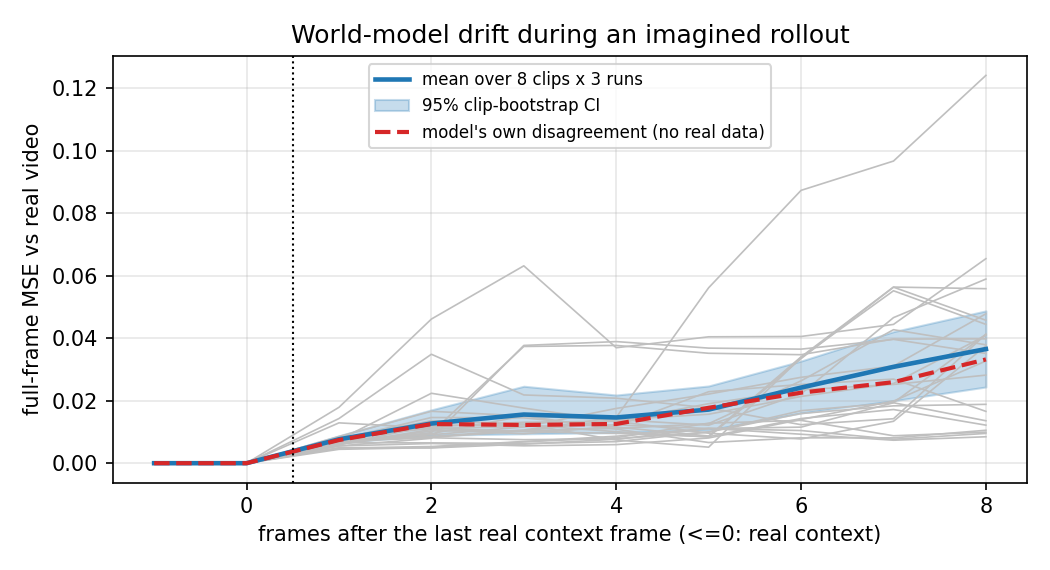

**Figure 2. Is the model's disagreement calibrated against reality?**

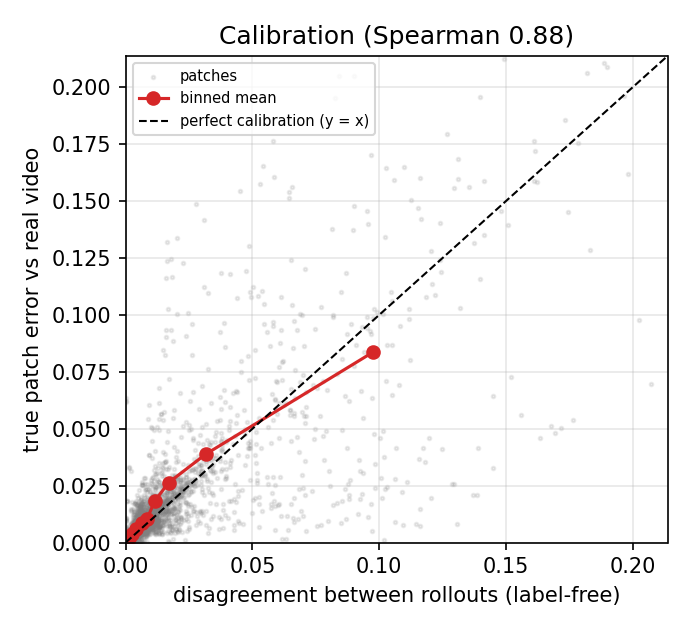

**Figure 3. Accuracy of the audits (1 real patch per frame)**

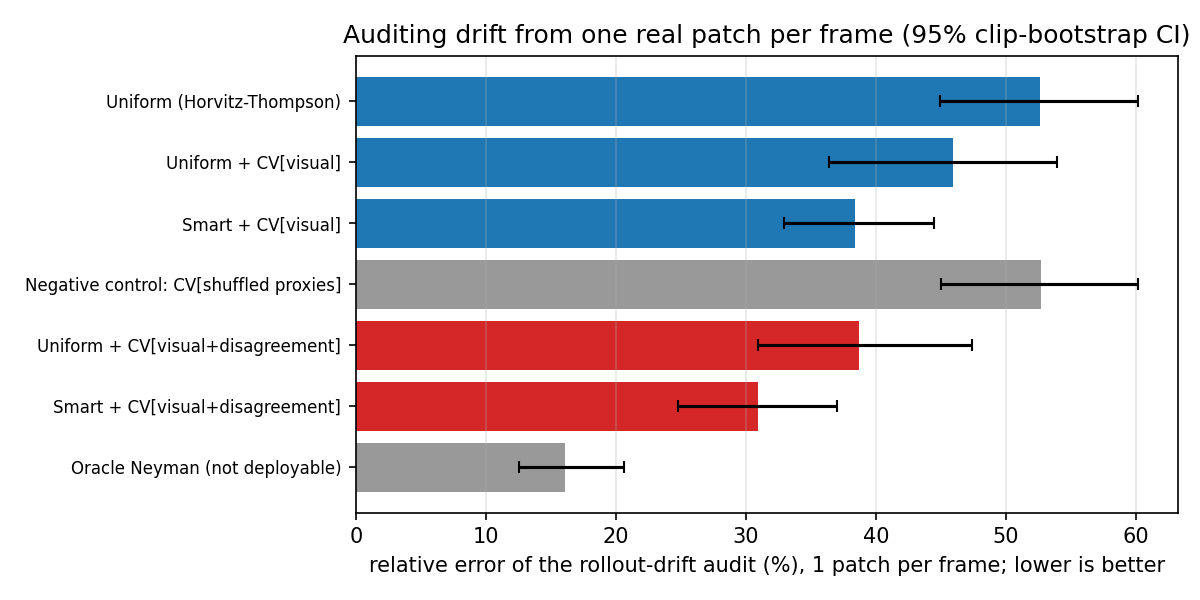

**Figure 4. Accuracy versus the number of real patches inspected**

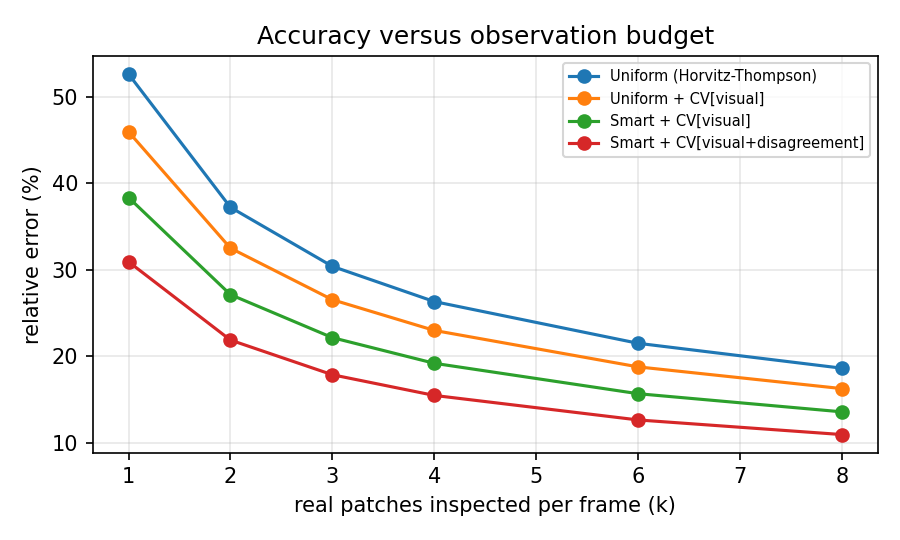

**Figure 5. One frame: reality, imagination, error, disagreement, sampling**

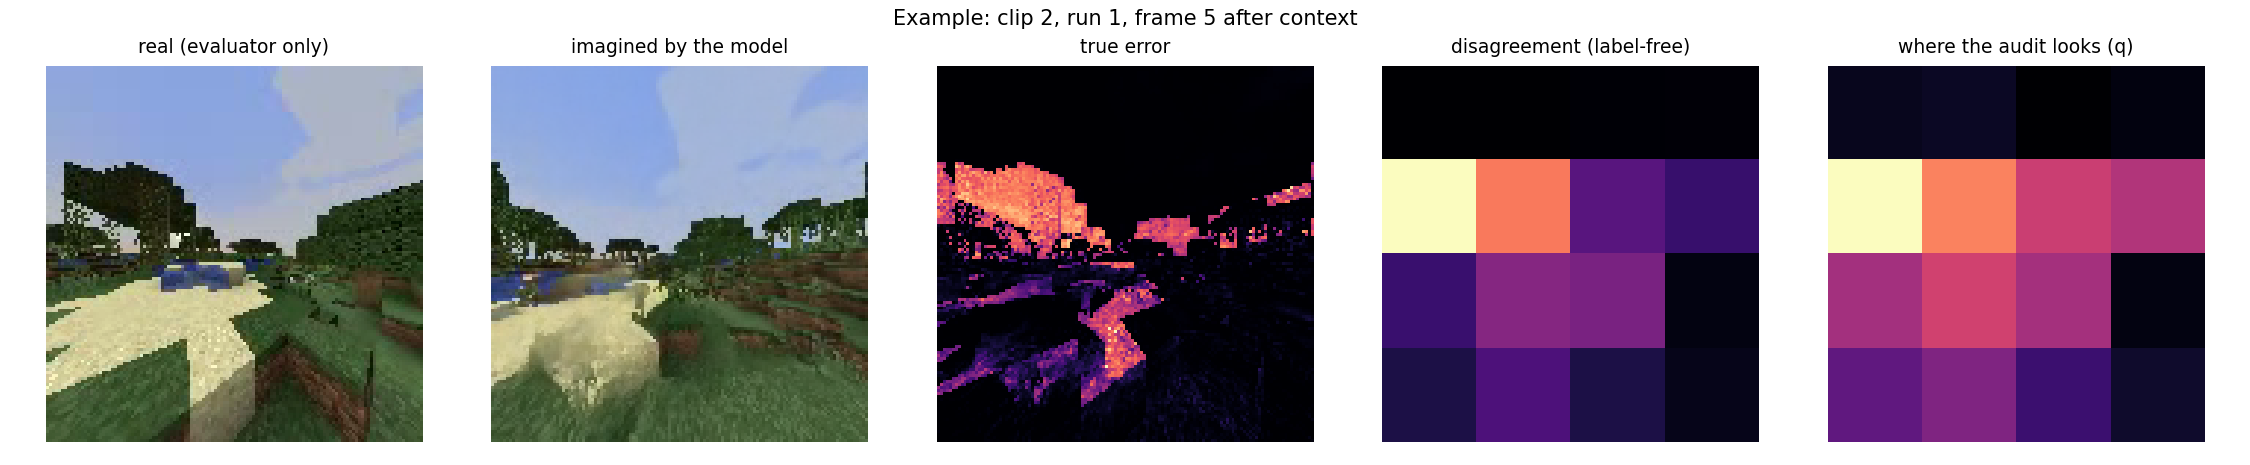

In [12]:
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RESULTS}/results.md").read()))
for f, title in [("fig1_drift.png", "Figure 1. Drift of the imagined rollout, and the model's own disagreement"),
                 ("fig2_calibration.png", "Figure 2. Is the model's disagreement calibrated against reality?"),
                 ("fig3_estimators.png", "Figure 3. Accuracy of the audits (1 real patch per frame)"),
                 ("fig4_budget.png", "Figure 4. Accuracy versus the number of real patches inspected"),
                 ("fig5_example.png", "Figure 5. One frame: reality, imagination, error, disagreement, sampling")]:
    p = f"{RESULTS}/{f}"
    if os.path.exists(p):
        display(Markdown(f"**{title}**")); display(Image(filename=p, width=900))

## 7. Summary

The disagreement between rollouts closely tracks the real error (Spearman 0.88, calibration slope 0.91). With one real patch per frame, smart sampling with the disagreement control variate reduces the audit variance to 0.35 of uniform sampling (95% CI 0.25–0.46), equivalent to about 2.9× more observations, while every estimator remains unbiased.

## 8. Export

In [13]:
for log in glob.glob(f"{WORK}/generation_run*.log"):
    shutil.copy(log, RESULTS)
shutil.copy(AUDIT, RESULTS)
shutil.copy(f"{REPO}/df_dump_run.py", RESULTS)
archive = shutil.make_archive(f"{WORK}/wm_audit_results", "zip", RESULTS)
print("results:", archive)
print("raw rollouts kept in:", DUMP_ROOT)

results: /kaggle/working/wm_audit_results.zip
raw rollouts kept in: /kaggle/working/wm_audit_data
